# AutoML experiments (FLAML)

**Goal:** after the hand-built experiments, see whether an automated search over model families and
hyperparameters finds something we missed. The assignment allows AutoML once a manual approach is
done.

**Tool:** [FLAML](https://github.com/microsoft/FLAML) (Microsoft). It searches LightGBM, XGBoost,
random forest, Extra Trees and L1 logistic regression within a time budget, using a cost-aware
search that tries cheap configurations first. We chose it over AutoGluon because it is lightweight
and accepts **our own CV splitters**, so it optimises the same objective as our manual experiments.

**What we already know:**
- **Unseen subjects** (E, J; 54% of test): grouped AUC is only 0.50–0.59 for every model so far, and
  their score levels across subjects are wrong (`random_forest.ipynb` §8–9).
- **Known subjects** (46% of test): the hybrid features (per-subject z-score + subject one-hot) work.
  The best so far is a random forest + gradient boosting blend at out-of-fold AUC **0.868**
  (leaderboard proxy 0.736).

**Risk to watch:** AutoML tries hundreds of configurations against the same 5 folds. With only 11
subjects, the "best" grouped configuration may just fit the way those folds happen to split. We
re-check it on a different split (leave-one-subject-out).

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

> **Metric correction (2026-10-15).** The leaderboard scores **ROC AUC on submitted
> probabilities**, not accuracy. The leaderboard showed it: an all-1s file scored exactly 0.50000,
> which is what AUC gives any constant prediction, and our 0/1-label hybrid scored only 0.586,
> although its known-subject AUC is about 0.89. Submitting the same model's *probabilities* scored
> **0.70**. This notebook has been re-run with AUC as the metric. Models are chosen by AUC,
> submissions contain P(class 1), and threshold tuning has been removed, because AUC does not depend
> on a threshold. Some tables still show accuracy for reference.

In [1]:
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from flaml import AutoML
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")  # LightGBM / FLAML info-level warnings
RANDOM_STATE = 42
TIME_UNSEEN = 300   # seconds of AutoML search for experiment 1
TIME_KNOWN = 600    # seconds of AutoML search for experiment 2
ESTIMATORS = ["lgbm", "xgboost", "rf", "extra_tree", "lrl1"]

## 1. Load data and build features (same as `gradient_boosting.ipynb` section 2)

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")
sample_solution = pd.read_csv("sample_solution.csv")
y = train["output"]
groups = train["subject"].to_numpy(dtype=object)  # FLAML needs a plain numpy array for groups

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    return pd.get_dummies(X, columns=["state"], dtype=int)

X_raw = prep(train)
X_test_raw = prep(test).reindex(columns=X_raw.columns, fill_value=0)
const_cols = X_raw.columns[X_raw.nunique() <= 1]
X_raw = X_raw.drop(columns=const_cols)
X_test_raw = X_test_raw.drop(columns=const_cols)
sensor_cols = [c for c in X_raw.columns if c[0] in "xyz" and c[1:].isdigit()]

both = pd.concat([X_raw, X_test_raw], ignore_index=True)
subj_all = pd.concat([train.subject, test.subject], ignore_index=True)
g = both[sensor_cols].groupby(subj_all.values)
both[sensor_cols] = ((both[sensor_cols] - g.transform("mean")) / g.transform("std").replace(0, np.nan)).fillna(0)
subj_onehot = pd.get_dummies(subj_all, prefix="subj", dtype=int).reindex(
    columns=[f"subj_{s}" for s in sorted(train.subject.unique())], fill_value=0)
both = pd.concat([both, subj_onehot], axis=1)
X_hyb = both.iloc[:len(train)].reset_index(drop=True)
X_test_hyb = both.iloc[len(train):].reset_index(drop=True)

known = test.subject.isin(train.subject.unique()).values
test_mix = test.subject[known].value_counts(normalize=True)
print(f"raw: {X_raw.shape[1]} features; hybrid: {X_hyb.shape[1]} features; known-subject test rows: {known.mean():.1%}")

raw: 564 features; hybrid: 575 features; known-subject test rows: 45.7%


## 2. Evaluation helpers

AutoML optimises **ROC AUC**, the competition metric. Known-subject candidates are scored with
stratified out-of-fold AUC and the leaderboard proxy.

**Leaderboard proxy.** 54% of test rows come from unseen subjects (E, J). Our submissions give
those rows a constant score, the training class-1 rate (0.845), because no model has ranked unseen
subjects better than that (see `automl.ipynb` §7). To estimate the leaderboard AUC from training data
alone, `lb_proxy` picks 300 random groups of training subjects that together cover 45–60% of rows. It
gives their rows the constant, gives every other row the model's out-of-fold probability, and
averages the pooled AUC. Against real submissions, the proxy gave **0.753** for the submission that
scored **0.70**, and **0.720** for one that scored **0.68**. So it reads about 0.04–0.05 high, but it
puts submissions in the right order.

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)

PRIOR = (y == 1).mean()
g_arr = np.asarray(groups, dtype=object)
_sizes = pd.Series(g_arr).value_counts()
_all = [c for r in range(3, 8) for c in itertools.combinations(sorted(_sizes.index), r)
        if 0.45 <= _sizes[list(c)].sum() / len(g_arr) <= 0.60]
_rng = np.random.default_rng(RANDOM_STATE)
proxy_subsets = [_all[i] for i in _rng.choice(len(_all), 300, replace=False)]

def lb_proxy(p_known, p_unseen=None):
    """Mean pooled AUC when ~54% of rows (random subject groups) get p_unseen (default: the
    constant PRIOR, as E/J do in our submissions) and the rest get out-of-fold p_known."""
    p_unseen = np.full(len(y), PRIOR) if p_unseen is None else np.asarray(p_unseen)
    return np.mean([roc_auc_score(y, np.where(np.isin(g_arr, s), p_unseen, p_known))
                    for s in proxy_subsets])

def within_subject_auc(p):
    """AUC inside each subject that has both classes."""
    return pd.Series({s: roc_auc_score(y[g_arr == s], p[g_arr == s])
                      for s in np.unique(g_arr) if y[g_arr == s].nunique() > 1})

def known_subject_scores(p):
    return {"auc": roc_auc_score(y, p), "lb_proxy": lb_proxy(p)}

def run_automl(X, split, time_budget, **kw):
    automl = AutoML()
    automl.fit(X, y, task="classification", metric="roc_auc", eval_method="cv", split_type=split,
               time_budget=time_budget, estimator_list=ESTIMATORS, seed=RANDOM_STATE, verbose=0, **kw)
    print(f"Best: {automl.best_estimator}  CV AUC = {1 - automl.best_loss:.4f}")
    print("Config:", {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                      for k, v in automl.best_config.items()})
    print("Best CV AUC per model family:",
          {k: round(1 - v, 4) for k, v in automl.best_loss_per_estimator.items() if v is not None and np.isfinite(v)})
    return automl

## 3. Experiment 1: AutoML on unseen subjects (raw features, GroupKFold)

**Hypothesis:** AutoML won't find transferable signal either. Its best GroupKFold AUC may look
better than our hand-tuned models (0.54–0.59), because it searches so many configurations against
the same 5 folds. When the chosen configuration is re-scored with **leave-one-subject-out** (11
different folds), its pooled AUC should fall back toward 0.5 or below.

In [4]:
automl_unseen = run_automl(X_raw, gkf, TIME_UNSEEN, groups=groups)

Best: extra_tree  CV AUC = 0.5885
Config: {'n_estimators': 64, 'max_leaves': 27, 'max_features': 0.6746, 'criterion': np.str_('entropy')}
Best CV AUC per model family: {'lgbm': 0.5775, 'xgboost': 0.5823, 'rf': 0.5773, 'extra_tree': 0.5885, 'lrl1': 0.4949}


In [5]:
logo_model = clone(automl_unseen.model.estimator)
p_logo = cross_val_predict(logo_model, X_raw, y, cv=LeaveOneGroupOut(), groups=groups, method="predict_proba")[:, 1]

per_subj = pd.DataFrame({"y": y.values, "p": p_logo, "subject": groups})
subj_auc = pd.Series({s: roc_auc_score(d.y, d.p) for s, d in per_subj.groupby("subject") if d.y.nunique() > 1})
print(f"Leave-one-subject-out: pooled AUC = {roc_auc_score(y, p_logo):.3f}, "
      f"mean within-subject AUC = {subj_auc.mean():.3f}")
subj_auc.round(3).rename("within-subject AUC (held out)").to_frame().T

Leave-one-subject-out: pooled AUC = 0.410, mean within-subject AUC = 0.563


,A,B,C,D,F,G,H,I,L,M
within-subject AUC (held out),0.686,0.62,0.475,0.546,0.523,0.538,0.525,0.757,0.56,0.4


**Interpretation:** the hypothesis held. After about 5 minutes of search, AutoML's best GroupKFold
AUC is **0.589** (Extra Trees, 64 trees with 27 leaves). That ties our best hand-tuned unseen-subject
models (0.59) and is above every other family: LightGBM, XGBoost and RF score 0.58, and L1 logistic
regression 0.49. On **leave-one-subject-out**:
- the pooled AUC falls to **0.410**, below chance;
- the **mean within-subject AUC is 0.563** (I 0.76, A 0.69, B 0.62, but M 0.40). The ranking inside
  a new subject is a little better than chance, but the score levels across subjects are wrong. The
  same pattern appears in `random_forest.ipynb` §8–9.

So AutoML doesn't change the conclusion for E and J. A searched configuration doesn't transfer as
pooled probabilities.

## 4. Experiment 2: AutoML in the hybrid setup (known subjects)

**Hypothesis:** on the hybrid features, AutoML will match or slightly beat our hand-tuned forest and
boosting. LightGBM or XGBoost with tuned leaf counts, column subsampling and regularisation is the
obvious candidate. Adding its probabilities to the forest + boosting blend may add a little more.

References recomputed on the same folds:
- the forest (500 trees);
- gradient boosting with the tuned settings from `gradient_boosting.ipynb` §6, run for **800 rounds
  without early stopping**, which a training-length check showed is better than early stopping.

**Caveat:** AutoML chooses its configuration on these same stratified folds, so its numbers are a
little more optimistic than the references'.

In [6]:
automl_known = run_automl(X_hyb, skf, TIME_KNOWN)

Best: extra_tree  CV AUC = 0.8901
Config: {'n_estimators': 1124, 'max_features': 0.119, 'max_leaves': 575, 'criterion': np.str_('entropy')}
Best CV AUC per model family: {'lgbm': 0.8766, 'xgboost': 0.867, 'rf': 0.8588, 'extra_tree': 0.8901, 'lrl1': 0.7548}


In [7]:
automl_model = clone(automl_known.model.estimator)
rf = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE)
hgb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=800, early_stopping=False, max_leaf_nodes=31,
                                     l2_regularization=1.0, max_features=0.3, random_state=RANDOM_STATE)

oof = {name: cross_val_predict(m, X_hyb, y, cv=skf, method="predict_proba")[:, 1]
       for name, m in [("random forest", rf), ("gradient boosting (800 rounds)", hgb),
                       (f"AutoML: {automl_known.best_estimator}", automl_model)]}
names = list(oof)
oof["blend rf + hgb"] = (oof[names[0]] + oof[names[1]]) / 2
oof["blend rf + hgb + AutoML"] = (oof[names[0]] + oof[names[1]] + oof[names[2]]) / 3

rows = {"constant (all rows)": {"auc": 0.5, "lb_proxy": lb_proxy(np.full(len(y), PRIOR))}}
rows.update({name: known_subject_scores(p) for name, p in oof.items()})
known_table = pd.DataFrame(rows).T
print("Correlation of OOF probabilities:")
print(pd.DataFrame({k: oof[k] for k in names}).corr().round(3))
known_table.round(4)

Correlation of OOF probabilities:
                                random forest  gradient boosting (800 rounds)  \
random forest                           1.000                           0.814   
gradient boosting (800 rounds)          0.814                           1.000   
AutoML: extra_tree                      0.961                           0.829   

                                AutoML: extra_tree  
random forest                                0.961  
gradient boosting (800 rounds)               0.829  
AutoML: extra_tree                           1.000  


,auc,lb_proxy
constant (all rows),0.5000,0.5000
random forest,0.8650,0.7352
gradient boosting (800 rounds),0.8678,0.7015
AutoML: extra_tree,0.8897,0.7515
blend rf + hgb,0.8689,0.7258
blend rf + hgb + AutoML,0.8814,0.7428


In [8]:
final_name = known_table.drop("constant (all rows)").lb_proxy.astype(float).idxmax()
print(f"Best for known subjects: {final_name}")
pd.DataFrame({final_name: within_subject_auc(oof[final_name]),
              "random forest": within_subject_auc(oof["random forest"])}).round(3).T

Best for known subjects: AutoML: extra_tree


,A,B,C,D,F,G,H,I,L,M
AutoML: extra_tree,0.873,0.869,0.702,0.573,0.811,0.714,0.703,0.863,0.90,0.845
random forest,0.847,0.810,0.669,0.560,0.783,0.696,0.549,0.806,0.86,0.780


**Interpretation:** the hypothesis was partly right, but the winner was unexpected. AutoML's best
model is **Extra Trees** with very large trees (up to 575 leaves) and few features per split (12%),
not LightGBM or XGBoost. It is the best known-subject model so far:
- **AUC 0.890 and proxy 0.752**, vs 0.865 and 0.735 for the forest;
- higher within-subject AUC than the forest for **every** subject (for example H 0.70 vs 0.55,
  M 0.85 vs 0.78, B 0.87 vs 0.81);
- gradient boosting with 800 rounds has the second-best AUC (0.868) but the *lowest* proxy (0.70).
  Its probabilities rank well within subjects, but their per-subject levels are less well calibrated;
- blending makes things worse (proxy 0.743 for the 3-way blend). Extra Trees is 0.96 correlated with
  the forest, so a blend mostly dilutes it with weaker versions of the same model.

**Robustness check (run separately, re-scored by AUC):** AutoML chose its configuration on the same
stratified folds it is scored on above, so we re-scored a fixed configuration
(`ExtraTreesClassifier(n_estimators=701, max_features=0.119, max_leaf_nodes=575,
criterion="entropy")`, from an earlier run of this search) against the forest and boosting on **two
fresh 5-fold splits** (random_state 7 and 123):

| AUC | rf | hgb (800 rounds) | rf + hgb | **Extra Trees** | rf + hgb + ET |
|---|---|---|---|---|---|
| seed 7 | 0.865 | 0.864 | 0.866 | **0.884** | 0.878 |
| seed 123 | 0.866 | 0.866 | 0.869 | **0.889** | 0.881 |

Extra Trees is best on both splits, by about 0.02 AUC, so the gain doesn't depend on one particular
split. AutoML's search depends on the time budget, so this run chose 1124 trees instead of 701, with
the other settings unchanged.

## 5. Feature importance of the AutoML model

Permutation importance on one stratified validation fold, scored by AUC, as in
`gradient_boosting.ipynb` §8, so the two can be compared directly.

**Hypothesis:** if AutoML found the same signal as the forest and boosting, the same features will
rank at the top (`z47`, `x40`, `phase`, `subj_G`).

Features with importance > 0.002: 9


subj_G    0.0422
subj_K    0.0154
phase     0.0076
subj_M    0.0051
subj_A    0.0050
x40       0.0032
x3        0.0029
subj_D    0.0028
subj_C    0.0024
z119      0.0012
dtype: float64

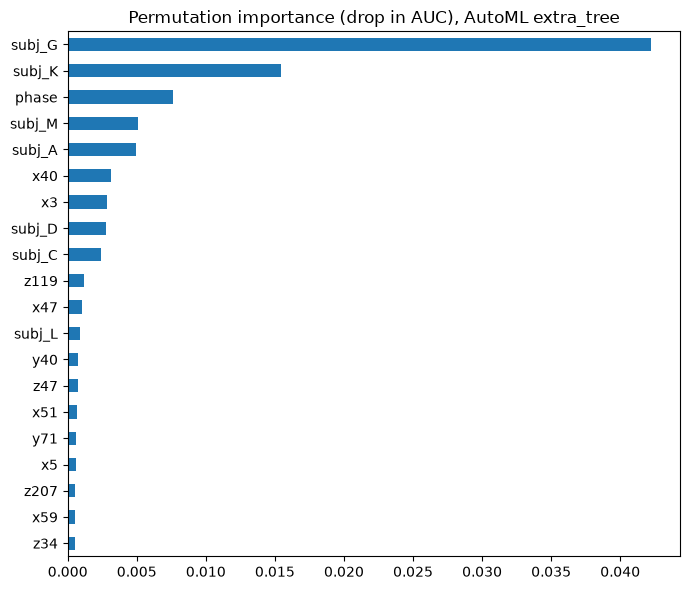

In [9]:
tr_idx, va_idx = next(skf.split(X_hyb, y))
imp_model = clone(automl_known.model.estimator).fit(X_hyb.iloc[tr_idx], y.iloc[tr_idx])
perm = permutation_importance(imp_model, X_hyb.iloc[va_idx], y.iloc[va_idx], scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_hyb.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot.barh(figsize=(7, 6), title=f"Permutation importance (drop in AUC), AutoML {automl_known.best_estimator}")
plt.tight_layout()
print(f"Features with importance > 0.002: {(perm_imp > 0.002).sum()}")
perm_imp.head(10).round(4)

**Interpretation:** the hypothesis was wrong in an informative way. The Extra Trees model leans on
**subject identity** much more than gradient boosting did. `subj_G` (0.042) is about 13× larger than
any sensor feature, and six subject columns are in the top 10. Then come `phase` (0.008) and only
three sensor features: `x40` (0.003, also in boosting's top 2), `x3` and `z119`. So much of its gain
comes from learning each subject's class-0 rate precisely. Under a pooled AUC that is valuable: it
puts each known subject at the right level. It also explains why none of this transfers to E and
J.

## 6. Hybrid submission (probabilities)

Fit the best known-subject option on all training rows and write its probabilities for the
known-subject test rows. E and J get the constant training class-1 rate.

In [10]:
models = {names[0]: rf, names[1]: hgb, names[2]: automl_model}
members = {"blend rf + hgb": names[:2], "blend rf + hgb + AutoML": names}.get(final_name, [final_name])
p_test_known = np.mean([clone(models[n]).fit(X_hyb, y).predict_proba(X_test_hyb[known])[:, 1] for n in members], axis=0)

automl_hybrid = sample_solution.copy().astype({"output": float})
automl_hybrid["output"] = PRIOR
automl_hybrid.loc[known, "output"] = p_test_known
automl_hybrid.to_csv("submission_automl_hybrid_proba.csv", index=False)
print(f"Model for known subjects: {final_name}; E/J rows: constant {PRIOR:.3f}")
automl_hybrid.output[known].groupby(test.subject[known].values).mean().round(3).rename("mean P(class 1), known subjects")

Model for known subjects: AutoML: extra_tree; E/J rows: constant 0.845


A    0.958
B    0.845
C    0.749
D    0.929
F    0.759
G    0.481
H    0.801
I    0.952
K    0.991
L    0.908
M    0.762
Name: mean P(class 1), known subjects, dtype: float64

**Interpretation:** the mean P(class 1) for each known subject closely tracks the training rates
(G 0.48 vs 0.49, C 0.75 vs 0.76, K 0.99 vs 1.00). E and J get 0.845. This is the submission strategy
that scored **0.70** on the leaderboard (`submission_et_hybrid_proba.csv`, made with the 701-tree
configuration). The proxy for this run is 0.752.

## 7. Leaderboard check: what should unseen subjects E and J get?

The public leaderboard gave us direct evidence about the metric and about E/J:

| File | Content | Public score |
|---|---|---|
| `submission_random_forest.csv` | 0/1 labels, all 1s | 0.50000 |
| `submission_adaboost.csv` | 0/1 labels, almost all 1s | 0.50310 |
| `submission_nn_hybrid.csv` | 0/1 labels, MLP hybrid | 0.51890 |
| `submission_gb_hybrid.csv` | 0/1 labels, rf + hgb hybrid | 0.55432 |
| `submission_hybrid.csv` | 0/1 labels, forest hybrid | 0.57873 |
| `submission_automl_hybrid.csv` | 0/1 labels, Extra Trees hybrid | 0.58565 |
| `submission_et_hybrid_proba.csv` | **probabilities**, Extra Trees hybrid, E/J = 0.845 | **0.70** |
| `submission_et_known_et_unseen.csv` | probabilities, Extra Trees hybrid, E/J = Extra Trees on raw features | 0.68 |
| (partner) `xgboost_optimized_submission.csv` | probabilities, XGBoost on all rows | 0.6998 |

An all-1s file scoring exactly 0.5 is what showed us the metric is AUC. Switching the same Extra Trees
hybrid from labels to probabilities was worth **+0.12**.

**Hypothesis:** for E and J, a model's probabilities won't beat a constant, because every
leave-one-subject-out test so far has shown pooled AUC at or below 0.5 on unseen subjects. We test
several model families that our partner isn't already using (they cover XGBoost, CatBoost, LightGBM
and logistic regression). Each one gets leave-one-subject-out probabilities, and the "unseen" share
of the leaderboard proxy is filled with them instead of the constant.

In [11]:
unseen_models = {
    "Extra Trees (AutoML known-subject config, raw features)": clone(automl_known.model.estimator),
    "random forest (raw)": RandomForestClassifier(n_estimators=500, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
    "kNN, k=50": make_pipeline(StandardScaler(), KNeighborsClassifier(50)),
    "LDA, shrinkage": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")),
    "MLP (64,), alpha=1": make_pipeline(StandardScaler(), MLPClassifier((64,), alpha=1.0, early_stopping=True,
                                                                       max_iter=500, random_state=RANDOM_STATE)),
}
p_known_best = oof[final_name]
p_unseen = {name: cross_val_predict(m, X_raw, y, cv=LeaveOneGroupOut(), groups=groups, method="predict_proba")[:, 1]
            for name, m in unseen_models.items()}
fill_table = pd.DataFrame(
    {f"constant {PRIOR:.3f}": {"lb_proxy": lb_proxy(p_known_best), "within_subject_auc": 0.5}}
    | {name: {"lb_proxy": lb_proxy(p_known_best, p), "within_subject_auc": within_subject_auc(p).mean()}
       for name, p in p_unseen.items()}).T
fill_table.sort_values("lb_proxy", ascending=False).round(4)

,lb_proxy,within_subject_auc
constant 0.845,0.7515,0.5000
"Extra Trees (AutoML known-subject config, raw features)",0.7221,0.5516
"LDA, shrinkage",0.7198,0.5338
random forest (raw),0.7147,0.5194
"kNN, k=50",0.7130,0.5524
"MLP (64,), alpha=1",0.6977,0.5228


In [12]:
# Reproduce the 0.68 submission: same known-subject probabilities, Extra Trees (raw) for E/J
et_raw = clone(automl_known.model.estimator).fit(X_raw, y)
variant = automl_hybrid.copy()
variant.loc[~known, "output"] = et_raw.predict_proba(X_test_raw[~known])[:, 1]
variant.to_csv("submission_automl_hybrid_proba_et_unseen.csv", index=False)
variant.output[~known].describe().round(3)

count    941.000
mean       0.795
std        0.149
min        0.101
25%        0.757
50%        0.826
75%        0.882
max        0.992
Name: output, dtype: float64

**Interpretation:** the hypothesis held. The constant gives the highest proxy (**0.752**). Every model
family lowers it: Extra Trees 0.722, LDA 0.720, random forest 0.715, kNN 0.713, MLP 0.698. That
happens even though all of them rank rows inside an unseen subject slightly better than chance
(within-subject AUC 0.52–0.55): their score levels across subjects are wrong, and that costs more than
the ranking gains. The leaderboard confirmed the top two: the constant scored **0.70** and Extra Trees
for E/J scored **0.68**, the same 0.03 gap as the proxy. The proxy reads about 0.05 too high, but it
orders submissions correctly.

## Summary and next steps

**Result:**

| Known-subject model (hybrid features) | Out-of-fold AUC | Leaderboard proxy |
|---|---|---|
| constant | 0.500 | 0.500 |
| gradient boosting, 800 rounds | 0.868 | 0.702 |
| random forest | 0.865 | 0.735 |
| blend rf + hgb + Extra Trees | 0.881 | 0.743 |
| **AutoML: Extra Trees** | **0.890** | **0.752** |

**Best leaderboard score: 0.70** (Extra Trees probabilities for known subjects, 0.845 for E/J). That
ties our partner's best XGBoost (0.6998).

**What we learned:**
- **The metric is ROC AUC on probabilities.** Switching from 0/1 labels to probabilities was worth
  +0.12 on the leaderboard with the same model.
- **Unseen subjects (54% of test):** AutoML matches our best grouped AUC (0.59), but as pooled
  probabilities nothing beats a constant. Models rank rows *within* a new subject a little (0.52–0.57)
  but get the levels across subjects wrong. The leaderboard confirmed it (0.70 vs 0.68).
- **Known subjects:** AutoML found the strongest model, Extra Trees with big trees and strong feature
  subsampling. It gains about 0.02 AUC over the forest, holds up on fresh folds, and relies heavily on
  subject identity to set each subject's level.

**Next steps:**
1. **Within-subject ranking for E and J at a constant level:** score = 0.845 + a small multiple of
   each row's rank *within its subject*, using the per-subject normalised Extra Trees model
   (`random_forest.ipynb` §8: within-subject AUC 0.57). Every row keeps the safe level, and rows can
   still move up or down inside E or J. It can be tested with the proxy before using a submission.
2. SHAP for the explainability part of the grade: `x40`, `x47` and `z47` (transfer) and `phase`.

*Reproducibility:* FLAML's search depends on the time budget, so re-runs can choose a slightly
different configuration (701 vs 1124 trees between our runs). *Runtime:* about 21 minutes.